## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [2]:
# Your Phase 1 solution to the problem goes here.

#Q1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

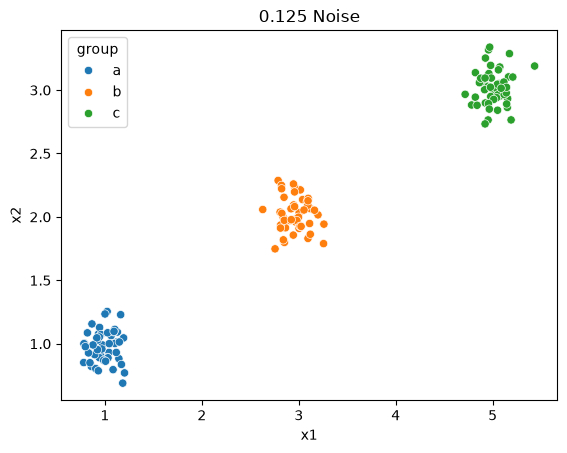

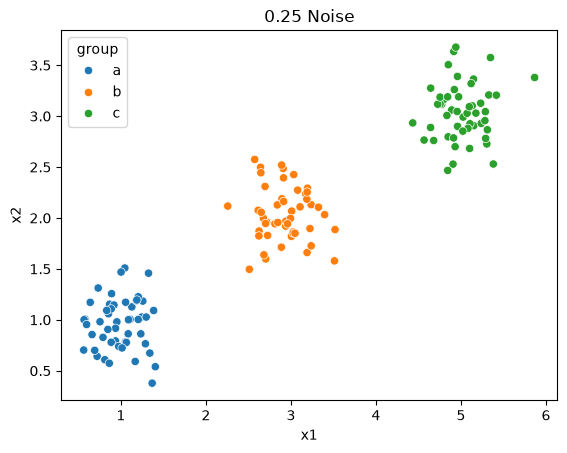

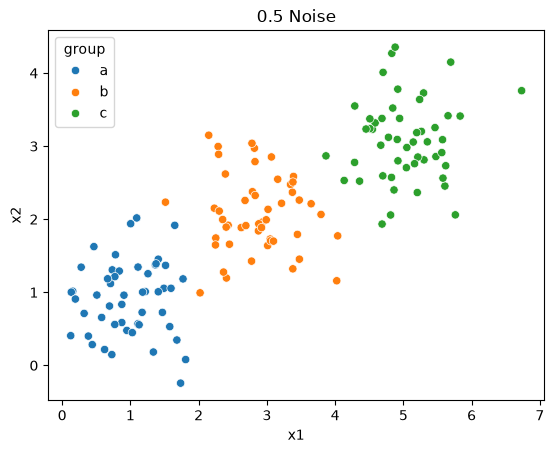

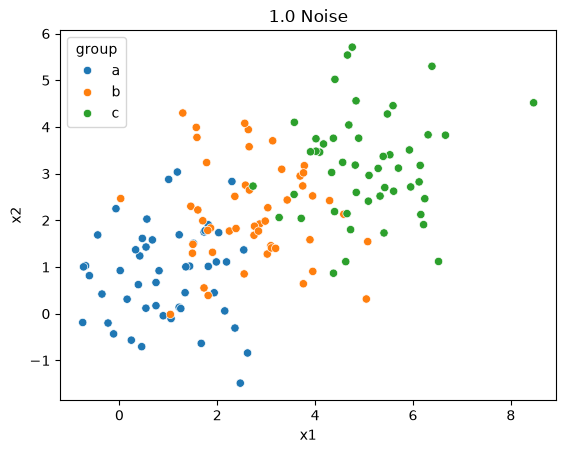

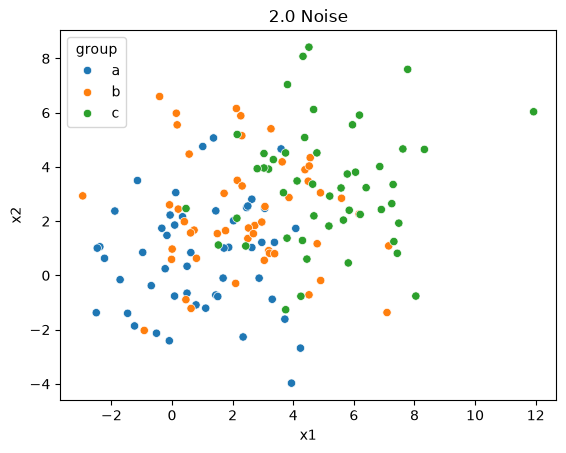

In [3]:
#Q2
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
plt.title("0.125 Noise")
plt.show()

sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
plt.title("0.25 Noise")
plt.show()

sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
plt.title("0.5 Noise")
plt.show()

sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
plt.title("1.0 Noise")
plt.show()

sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
plt.title("2.0 Noise")
plt.show()

Q1.2) As the noise gets larger, the groupings become less distinct. When noise = 0.125, we see three disinct groups for a, b, and c. As noise increases the groupings become less tight and start to overlap with other clusters. When noise = 2, we see that the clusters are significantly less distinct, with overlap between all three groups.

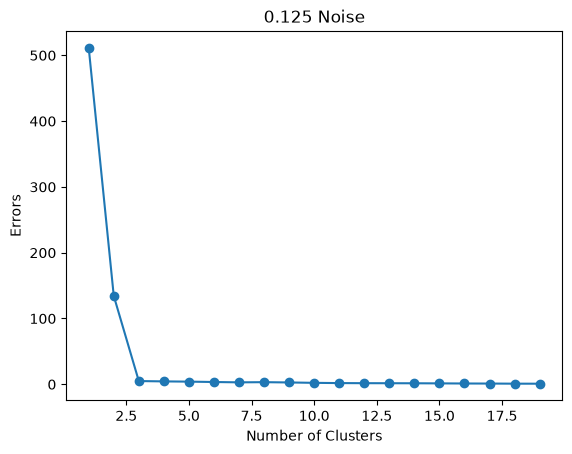

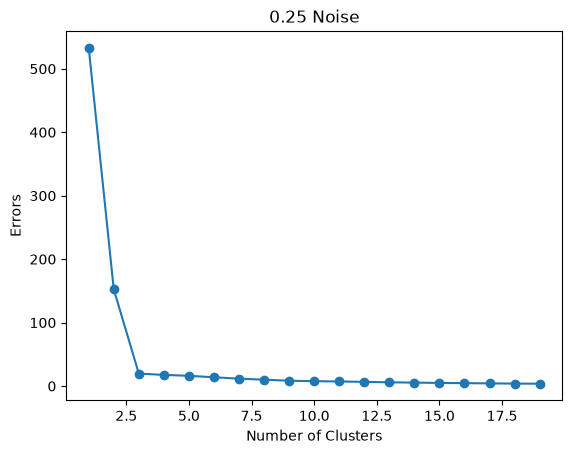

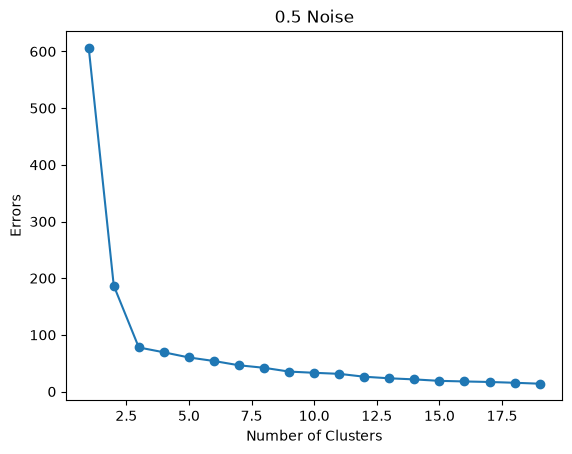

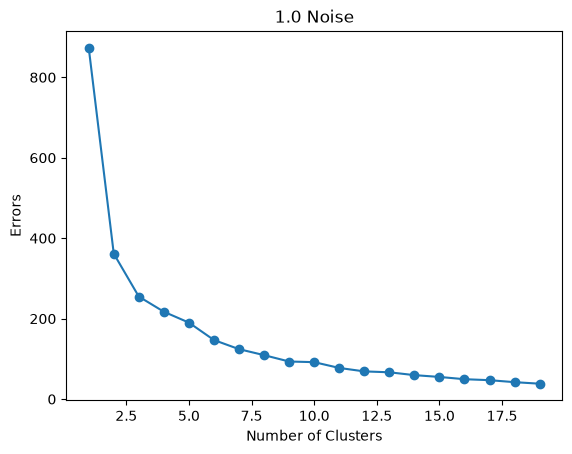

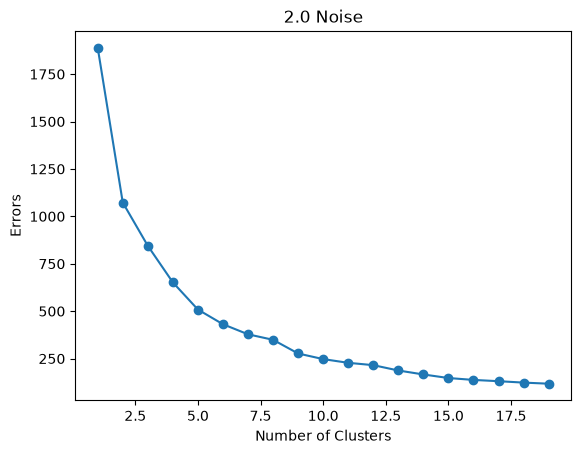

In [9]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df0_125[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("0.125 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df0_25[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("0.25 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df0_5[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("0.5 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df1_0[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("1.0 Noise")
plt.show()

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(df2_0[["x1", "x2"]])
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("2.0 Noise")
plt.show()



Q 1.3) As noises increases the plot starts to exihibit more of a gradual behavior rather than a sharp decline before leveling off. When the noise is lower, there is a sharp decrease in the error before starting to level out when the number of clusters, k, = 3. As noises increases, the error decreases gradually, making it harder to pinpoint exactly where the elbow is. Th error also grows larger, as shown by the large values on the y-axis, as noises increases.

Q 1.4) The elbow shows that adding more clusters reduces the error significantly in the beginning before the improvements start to plateau with marginal improvements. When the noise was lower, the error dropped sharply before leveling out at around k = 3, which suggests that 3 clusters are optimal, with more clusters providing minimal improvement. When noise increases, the elbow becomes less distinct since the data is more spread out with less distinct clusters, therefore making it harder to find the optimal number of clusters

In [5]:
#Q2.1
import pandas as pd
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
print(df)
df_2020 = df[df["Year"] == 2020]
cleaned = df_2020.dropna()
#dropping index column redundant 
cleaned = cleaned.drop(columns=["index"])
cleaned


      index  Year      Country  Spending (2020 USD)  Percent of GDP  \
0         0  1988  Afghanistan                  NaN             NaN   
1         1  1989  Afghanistan                  NaN             NaN   
2         2  1990  Afghanistan                  NaN             NaN   
3         3  1991  Afghanistan                  NaN             NaN   
4         4  1992  Afghanistan                  NaN             NaN   
...     ...   ...          ...                  ...             ...   
5877   5877  2017     Zimbabwe           571.920778        0.003878   
5878   5878  2018     Zimbabwe           638.310913        0.003093   
5879   5879  2019     Zimbabwe           796.573534        0.005348   
5880   5880  2020     Zimbabwe             8.622460        0.000054   
5881   5881  2021     Zimbabwe            34.175047        0.000135   

      Percent of Government Spending  Spending per Capita  
0                                NaN                  NaN  
1                          

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...
5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


Q2.1) The index column could also be dropped since it provides the same information row number infromation already provided by pandas.

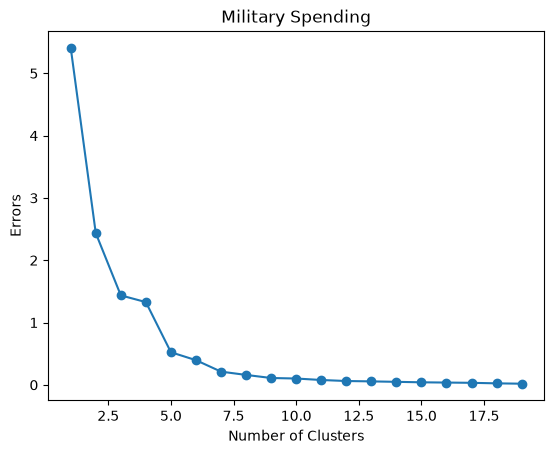

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[

In [ ]:
from sklearn.cluster import KMeans

spending = cleaned[["Spending (2020 USD)", "Spending per Capita"]]
normalized = (spending - spending.min()) / (spending.max() - spending.min())

errors = []
for k in range(1, 20):
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(normalized)
    errors.append(model.inertia_)

plt.plot(range(1, 20), errors, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Errors")
plt.title("Military Spending")
plt.show()

model = KMeans(n_clusters=5, random_state=1)
model.fit(normalized)
cleaned["cluster"] = model.labels_

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]